# Using Unified CEBRA: cross-recordings neural alignment, latent space exploration, and robustness to uneven behavioral coverage

This is a demo notebook to run a Unified CEBRA model (*[preprint coming]*, Célia Benquet, Hossein Mirzaei, Steffen Schneider, & Mackenzie Weygandt Mathis).

**Dataset:** Open-source rat hippocampus navigation dataset ([Grosmark & Buzáki, Science, 2016](https://www.science.org/doi/full/10.1126/science.aad1935)).

In this notebook you will learn how to: 
- Train a Unified CEBRA model, using our pytorch API
- Vizualize the resulting embeddings, either session-indexed or global.
- Decode position and direction from the embeddings as a way to measure the information contained.
- Investigate how position and direction are represented in the latent space.
- Investigate how the individual place cells contribute to these variables.
- Visualize latent spaces when individual sessions cover only part of the track.


In [1]:
#!pip install -q --pre 'cebra[datasets,demos,integrations]'

Full execution of this notebook can take ~30min depending on your hardware. If you would like to load a reference run, set the `USE_CACHED_MODEL` variable to `True` to download [data from a reference run](https://figshare.com/ndownloader/articles/29275358?private_link=ae8099185f5e2f5e8185) which will allow you to render all plots. Set to `False` if the model and decoding should be re-run.

In [2]:
USE_CACHED_MODEL = True
# Reference run (unified, masked, 5000 steps, run 0), downloaded from figshare to ./model/ below
MODEL_PATH = "model/261113-hippocampus-unified-run0.pt"

## Set up package imports and load the demo data

In [3]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from matplotlib.colors import ListedColormap, BoundaryNorm
import os
import seaborn as sns
import sklearn.metrics
import torch
import numpy as np

import cebra
from cebra.integrations.plotly import plot_embedding_interactive
from plotly.subplots import make_subplots

device = "cuda" if torch.cuda.is_available() else "cpu"

In [4]:
# Load the datasets
hippocampus_a = cebra.datasets.init('rat-hippocampus-single-achilles')
hippocampus_b = cebra.datasets.init('rat-hippocampus-single-buddy')
hippocampus_c = cebra.datasets.init('rat-hippocampus-single-cicero')
hippocampus_g = cebra.datasets.init('rat-hippocampus-single-gatsby')

datasets = [hippocampus_a, hippocampus_b, hippocampus_c, hippocampus_g]

/home/celia/CEBRA/cebra/__init__.py:123: UserWarning: Your code triggered a lazy import of cebra.datasets. While this will (likely) work, it is recommended to add an explicit import statement to you code instead. To disable this warning, you can run ``cebra.allow_lazy_imports()``.
  warnings.warn(


In [5]:
# Download the cached model from figshare, once. The figshare item comes as one zip; only the model file is kept.
if USE_CACHED_MODEL and not os.path.exists(MODEL_PATH):
    print("Downloading cached model. If you want to re-run, set USE_CACHED_MODEL to False.")
    import io, requests, zipfile
    url = "https://ndownloader.figshare.com/articles/29275358?private_link=ae8099185f5e2f5e8185"
    response = requests.get(url, timeout=600)
    content = io.BytesIO(response.content)
    if response.status_code == 200 and zipfile.is_zipfile(content):
        os.makedirs(os.path.dirname(MODEL_PATH), exist_ok=True)
        with zipfile.ZipFile(content) as archive:
            for member in archive.namelist():
                if os.path.basename(member) == os.path.basename(MODEL_PATH):
                    with archive.open(member) as f, open(MODEL_PATH, "wb") as out:
                        out.write(f.read())
    if not os.path.exists(MODEL_PATH):
        print(f"Download failed (HTTP {response.status_code}, {len(response.content)} bytes). Download "
              f"{os.path.basename(MODEL_PATH)} from https://figshare.com/s/ae8099185f5e2f5e8185 in a browser "
              "and put it in ./model/. Without it, the model is trained below (~30 min).")


In [6]:
# Split data and labels (labels we use later!)
train_data, valid_data = [], []
train_continuous_label, valid_continuous_label = [], []
for i, dataset in enumerate(datasets):
    split_idx = int(0.7 * len(dataset.neural)) #suggest: 5%-20% depending on your dataset size

    train_data.append(dataset.neural[:split_idx])
    valid_data.append(dataset.neural[split_idx:])

    train_continuous_label.append(dataset.continuous_index.numpy()[:split_idx])
    valid_continuous_label.append(dataset.continuous_index.numpy()[split_idx:])

train_datasets = [
    cebra.data.TensorDataset(
        neural=train_data[i], continuous=train_continuous_label[i], device=device
    )
    for i in range(len(train_data))
]

valid_datasets = [
    cebra.data.TensorDataset(valid_data[i], continuous=valid_continuous_label[i], device=device)
    for i in range(len(valid_data))
]

## Train a model using the torch API

In [7]:
# Hyperparameters
# NOTE: This would need to be adjusted based on your dataset and task
config = {"model_architecture": "offset10-model",
    "batch_size": 2048,
    "output_dimension": 32,
    "time_offsets": 10,
    "learning_rate": 0.0003,
    "num_hidden_units": 32,
    "temperature": 1,
    "max_iterations": 5000,
    "conditional": "time_delta",
    "verbose": True,
}

In [8]:
# Number of neurons = sum of neurons in all datasets
num_neurons = 0
for dataset in train_datasets:
    num_neurons += dataset.neural.shape[1]

# Define the dataset
dataset = cebra.data.UnifiedDataset(dataset for dataset in train_datasets)

# Set the masks for the dataset
# 'RandomNeuronMask' and 'RandomTimestepMask' are used to randomly mask neurons and timesteps
# during training, which helps the model to learn better representations.
dataset.set_masks({"RandomNeuronMask": (0.3, 0.9, 0.05),
                   "RandomTimestepMask": (0.3, 0.9, 0.05)})

dataset.to(device)

# Define the dataset loader
loader = cebra.data.UnifiedLoader(
    dataset,
    conditional=config["conditional"],
    num_steps=config["max_iterations"],
    batch_size=config["batch_size"],
    time_offset=config["time_offsets"],
)

dataset.to(device)

# Define the model
model = cebra.models.init(
    config["model_architecture"],
    num_neurons=num_neurons,
    num_units=config["num_hidden_units"],
    num_output=config["output_dimension"],
)
model.to(device)
dataset.configure_for(model)

criterion = cebra.models.FixedCosineInfoNCE(temperature=config["temperature"])
criterion.to(device)
optimizer = torch.optim.Adam(list(model.parameters()), lr=config["learning_rate"])

# Define the solver
solver = cebra.solver.UnifiedSolver(
    model=model, criterion=criterion, optimizer=optimizer, tqdm_on=config["verbose"]
)

In [9]:
if USE_CACHED_MODEL and os.path.exists(MODEL_PATH):
    checkpoint = torch.load(MODEL_PATH, map_location=device, weights_only=False)
    solver.load_state_dict(checkpoint, strict=True)
else:
    solver.fit(loader) # This step takes some time depending on your dataset and hardware
    solver.save(logdir="model", filename=os.path.basename(MODEL_PATH))

### Visualize the InfoNCE loss & goodness of fit

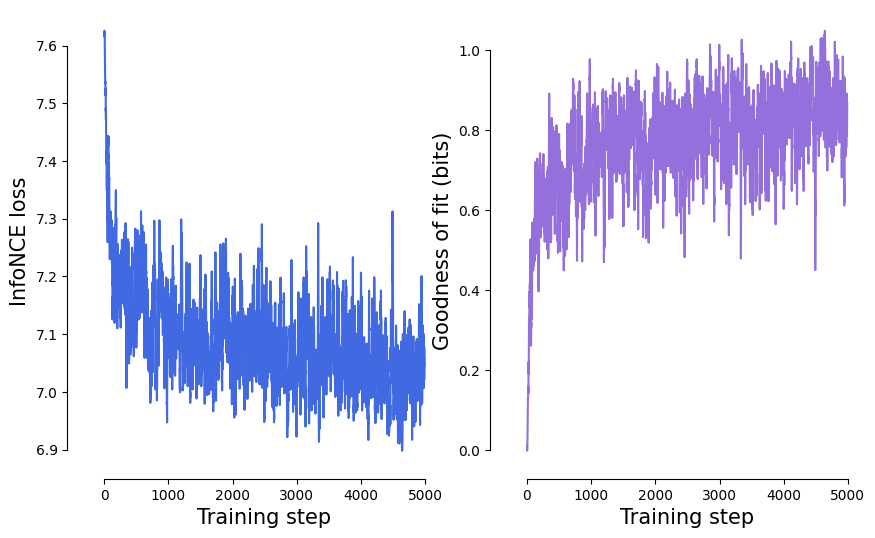

In [10]:
# We smooth the loss and goodness of fit curves for better visualization.
def smooth_curve(values, window_size=10):
    return np.convolve(values, np.ones(window_size) / window_size, mode='valid')

smoothed_loss = smooth_curve(solver.history, window_size=10)
smoothed_gof = smooth_curve(
    cebra.sklearn.metrics.infonce_to_goodness_of_fit(
        infonce=solver.history,
        batch_size=config["batch_size"],
        num_sessions=1
    ),
    window_size=10
)

# ... and plot the results
fig, axes = plt.subplots(1, 2, figsize=(10, 6))

axes[0].plot(smoothed_loss, c="royalblue")
axes[0].set_xlabel("Training step", fontsize=15)
axes[0].set_ylabel("InfoNCE loss", fontsize=15)

axes[1].plot(smoothed_gof, c="mediumpurple")
axes[1].set_xlabel("Training step", fontsize=15)
axes[1].set_ylabel("Goodness of fit (bits)", fontsize=15)

sns.despine(
    left=False,
    right=True,
    bottom=False,
    top=True,
    trim=True,
    offset={"bottom": 5, "left": 15},
)


### Get the session-indexed and global embeddings

In [11]:
solver = solver.to("cpu")

In [12]:
# This is similar to the multisession CEBRA-behavior API, but you add the labels at inference

embeddings = []
for i in range(len(train_datasets)):
    embeddings.append(solver.transform([train_datasets[j].neural.cpu() for j in range(len(train_datasets))],
                                     labels=[train_datasets[j].continuous.cpu() for j in range(len(train_datasets))], #NOTE: labels at inference
                                     session_id = i,
                                     batch_size=300).cpu().numpy())


# And we can also get the validation embeddings
val_embeddings = []
for i in range(len(train_datasets)):
    val_embeddings.append(solver.transform([valid_datasets[j].neural.cpu() for j in range(len(valid_datasets))],
                                     labels=[valid_datasets[j].continuous.cpu() for j in range(len(valid_datasets))],
                                     session_id = i,
                                     batch_size=300).cpu().numpy())

In [13]:
# And because the latent space is shared across all sessions, we can concatenate the embeddings
# into a single global embedding.

full_embedding = np.concatenate(embeddings, axis=0)
full_labels = np.concatenate([train_datasets[i].continuous_index.cpu().numpy() for i in range(len(train_datasets))], axis=0)

full_val_embedding = np.concatenate(val_embeddings, axis=0)
full_val_labels = np.concatenate([valid_datasets[i].continuous_index.cpu().numpy() for i in range(len(valid_datasets))], axis=0)

In [14]:
# Then we can plot the single-session embeddings and the global embedding.

alpha = 0.5

cols = len(embeddings) + 1
fig = make_subplots(
    rows=1,
    cols=cols,
    specs=[[{"type": "scatter3d"}, {"type": "scatter3d"}, {"type": "scatter3d"}, {"type": "scatter3d"}, {"type": "scatter3d"}]],
    subplot_titles=tuple(
        np.concatenate([np.array(
            [f"Rat {str(i+1)}" for i in range(len(embeddings))]
        ), np.array(["All rats"])])
    ),
    vertical_spacing=0,
    horizontal_spacing=0.0,
)

r_map = "magma"
l_map = "viridis"
for i in range(len(embeddings)):
    label = train_datasets[i].continuous.cpu().numpy()

    r_ind = label[:, 1] == 1
    l_ind = label[:, 2] == 1
    r_c = label[r_ind, 0]
    l_c = label[l_ind, 0]

    fig = cebra.plot_embedding_interactive(
        embeddings[i][r_ind],
        r_c,
        cmap=r_map,
        axis=fig,
        row=1,
        col=i+1,
        opacity=alpha,
        title="",
    )

    fig = cebra.plot_embedding_interactive(
        embeddings[i][l_ind],
        l_c,
        cmap=l_map,
        axis=fig,
        row=1,
        col=i+1,
        opacity=alpha,
        title="",
    )

r_ind = full_labels[:, 1] == 1
l_ind = full_labels[:, 2] == 1
r_c = full_labels[r_ind, 0]
l_c = full_labels[l_ind, 0]

fig = cebra.plot_embedding_interactive(
    full_embedding[r_ind],
    r_c,
    cmap=r_map,
    axis=fig,
    row=1,
    col=5,
    opacity=alpha,
    title="",
)

fig = cebra.plot_embedding_interactive(
    full_embedding[l_ind],
    l_c,
    cmap=l_map,
    axis=fig,
    row=1,
    col=5,
    opacity=alpha,
    title="",
)

dict_layout = dict(
        xaxis = dict(
            backgroundcolor="rgba(0, 0, 0, 0)",
            gridcolor="rgba(0, 0, 0, 0)",
            showbackground=True,
            zerolinecolor="white",
        ),
        yaxis = dict(
            backgroundcolor="rgba(0, 0, 0, 0)",
            gridcolor="rgba(0, 0, 0, 0)",
            showbackground=True,
            zerolinecolor="white",
        ),
        zaxis = dict(
            backgroundcolor="rgba(0, 0, 0, 0)",
            gridcolor="rgba(0, 0, 0, 0)",
            showbackground=True,
            zerolinecolor="white",
        ))

fig.update_layout(
    scene = dict_layout,
    scene2= dict_layout,
    scene3= dict_layout,
    scene4= dict_layout,
    scene5= dict_layout,
    margin=dict(l=0, r=0, t=30, b=0),
    width=650,
    height=200,
)

fig.show(
    renderer="notebook",
)

## Investigate how behavioral labels are represented in the embedding

The contrastive loss does not fix the axes of the embedding: any rotation of the embedding gives the same loss. A single
latent dimension therefore has no meaning of its own.

☝️ However, we can **(1)** decode behavior from the full embedding, as a measure of the information contained, and **(2)** look for the *directions* in the embedding that are defined by behavior, in this case, a position subspace and a direction axis.

### 1. Decode behavior from the full embedding

In [15]:
def decoding_pos_dir(embedding_train, embedding_test, label_train, label_test):
    """kNN decoding of position and direction. Returns position R2, direction R2 and median position error [m]."""
    pos_decoder = cebra.KNNDecoder(n_neighbors=36, metric="cosine")
    dir_decoder = cebra.KNNDecoder(n_neighbors=36, metric="cosine")

    pos_decoder.fit(embedding_train, label_train[:, 0])
    dir_decoder.fit(embedding_train, label_train[:, 1])

    pos_pred = pos_decoder.predict(embedding_test)
    dir_pred = dir_decoder.predict(embedding_test)

    pos_r2_score = sklearn.metrics.r2_score(label_test[:, 0], pos_pred)
    dir_r2_score = sklearn.metrics.r2_score(label_test[:, 1], dir_pred)
    pos_error = np.median(np.abs(label_test[:, 0] - pos_pred))
    return pos_r2_score, dir_r2_score, pos_error

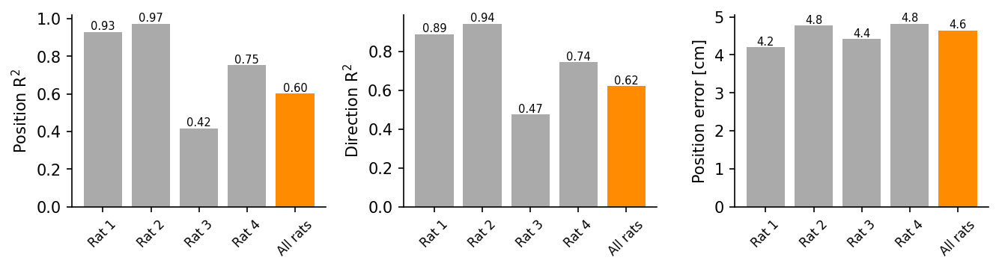

In [16]:
# Train the decoders on the train embedding and score them on the validation embedding, for each rat and for all rats
# together (possible because all rats share one latent space).
names, scores = [], []
for i in range(len(embeddings)):
    names.append(f"Rat {i + 1}")
    scores.append(decoding_pos_dir(embeddings[i], val_embeddings[i],
                                   train_datasets[i].continuous_index.cpu().numpy(),
                                   valid_datasets[i].continuous_index.cpu().numpy()))
names.append("All rats")
scores.append(decoding_pos_dir(full_embedding, full_val_embedding, full_labels, full_val_labels))
scores = np.array(scores)
scores[:, 2] *= 100   # position error in cm

fig, axes = plt.subplots(1, 3, figsize=(9, 2.5), dpi=150)
colors = ["#AAAAAA"] * len(embeddings) + ["#FF8C00"]
for ax, col, ylabel in zip(axes, range(3), ["Position R$^2$", "Direction R$^2$", "Position error [cm]"]):
    ax.bar(names, scores[:, col], color=colors)
    for x, v in enumerate(scores[:, col]):
        ax.text(x, v, f"{v:.2f}" if col < 2 else f"{v:.1f}", ha="center", va="bottom", fontsize=7)
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", labelrotation=45, labelsize=8)
    sns.despine(ax=ax)
plt.tight_layout()
plt.show()

### 2. Look for the *directions* in the embedding that are defined by behavior

We fit a linear model that explains the embedding from behavior: one term per position bin (8 bins on the 1.6 m
track) and one term for the running direction. 

The position-bin effects span the **position subspace** (we keep the
dimensions that explain 90% of their variance). The direction effect gives the **direction axis**. Both are fitted on
the train embedding of all rats together.

In [17]:
# NOTE: 8 position bins on the 1.6 m track, can be adjusted as needed
POS_EDGES = np.linspace(0.0, 1.6, 9)


def pos_bins(pos):
    return np.clip(np.digitize(pos, POS_EDGES[1:-1]), 0, len(POS_EDGES) - 2)


def fit_axes(emb, pos, direction, var_explained=0.90):
    """Linear model emb ~ one-hot(position bin) + direction.
    Returns the position subspace (D x k, orthonormal) and the unit direction axis (D,)."""
    n_bins = len(POS_EDGES) - 1
    X = np.zeros((len(emb), n_bins + 1))
    X[np.arange(len(emb)), pos_bins(pos)] = 1.0
    X[:, n_bins] = direction
    B, *_ = np.linalg.lstsq(X, emb, rcond=None)
    pos_effects = B[:n_bins] - B[:n_bins].mean(0, keepdims=True)   # centred position-bin effects
    _, s, vt = np.linalg.svd(pos_effects, full_matrices=False)
    k = int(np.searchsorted(np.cumsum(s ** 2) / np.sum(s ** 2), var_explained) + 1)
    return vt[:k].T, B[n_bins] / np.linalg.norm(B[n_bins])


pos_subspace, dir_axis = fit_axes(full_embedding, full_labels[:, 0], full_labels[:, 1])

#### Behavior along the position and direction axes

We project the embedding on the first position axis and on the direction axis, and compare with behavioral trace.

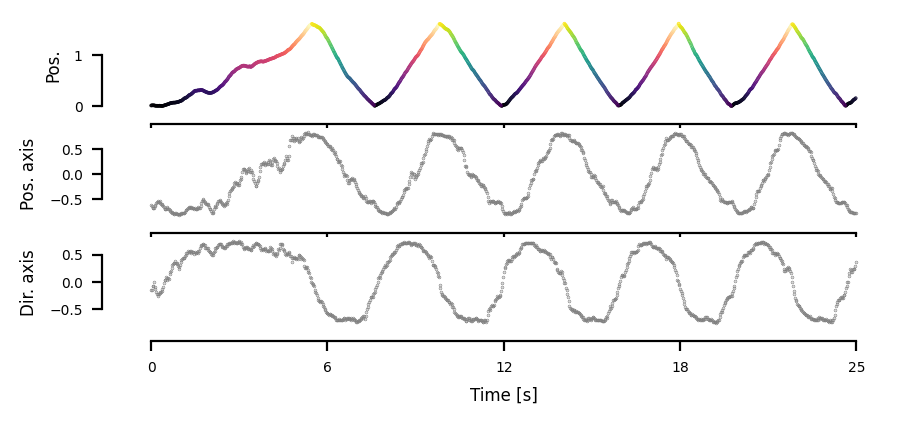

In [18]:
fig, ax = plt.subplots(3, 1, sharex=True, figsize=(5, 2), dpi=200)
n_points = 1000

labels = full_labels[:n_points, :]
proj_pos = full_embedding[:n_points] @ pos_subspace[:, 0]
proj_dir = full_embedding[:n_points] @ dir_axis
r_ind = labels[:, 1] == 1
l_ind = labels[:, 2] == 1

r_c = labels[r_ind, 0]
l_c = labels[l_ind, 0]

r_cmap = "magma"
l_cmap = "viridis"

ax[0].scatter(np.arange(n_points)[r_ind], labels[r_ind, 0], c=r_c, cmap=r_cmap, s=0.1)
ax[0].scatter(np.arange(n_points)[l_ind], labels[l_ind, 0], c=l_c, cmap=l_cmap, s=0.1)

ax[1].scatter(np.arange(n_points), proj_pos, c="grey", s=0.05)
ax[2].scatter(np.arange(n_points), proj_dir, c="grey", s=0.05)

ax[0].set_ylabel("Pos.", fontsize=6)
ax[1].set_ylabel("Pos. axis", fontsize=6)
ax[2].set_ylabel("Dir. axis", fontsize=6)
for a in ax:
    a.tick_params(labelsize=5)
    a.set_xticks(np.linspace(0, n_points, 5), np.linspace(0, 0.025 * n_points, 5, dtype=int))
ax[2].set_xlabel("Time [s]", fontsize=6)

sns.despine(
    left=False,
    right=True,
    bottom=False,
    top=True,
    trim=True,
    offset={"bottom": 5, "left": 5},
)

#### ... and corresponding flow-field plot

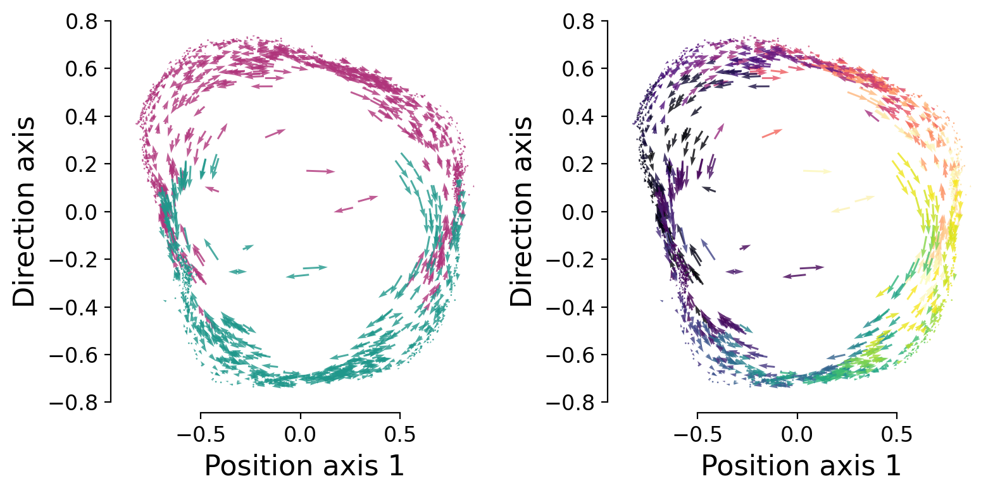

In [19]:
skip = 30

data = np.stack([full_embedding @ pos_subspace[:, 0], full_embedding @ dir_axis], axis=1)[::skip, :]

dt = 0.01
velocities = np.diff(data, axis=0) / dt
positions = 0.5 * (data[:-1] + data[1:])

labels = full_labels[::skip, :][1:, :]
r_ind = labels[:, 1] == 1
l_ind = labels[:, 2] == 1

fig, ax = plt.subplots(1, 2, figsize=(8, 4), dpi=200)

ax[0].quiver(positions[r_ind, 0], positions[r_ind, 1],
             velocities[r_ind, 0], velocities[r_ind, 1], color="#AF347B", alpha=0.8, width=0.005)
ax[0].quiver(positions[l_ind, 0], positions[l_ind, 1],
             velocities[l_ind, 0], velocities[l_ind, 1], color="#1F978B", alpha=0.8, width=0.005)

l_cmap = plt.cm.viridis
r_cmap = plt.cm.magma
r_c = labels[r_ind, 0] / dt
l_c = labels[l_ind, 0] / dt
norm = plt.Normalize(vmin=0 / dt, vmax=1.6 / dt)

ax[1].quiver(positions[r_ind, 0], positions[r_ind, 1],
             velocities[r_ind, 0], velocities[r_ind, 1], color=r_cmap(norm(r_c)), alpha=0.8, width=0.005)
ax[1].quiver(positions[l_ind, 0], positions[l_ind, 1],
             velocities[l_ind, 0], velocities[l_ind, 1], color=l_cmap(norm(l_c)), alpha=0.8, width=0.005)

for a in ax:
    a.set_xlabel("Position axis 1", fontsize=16)
    a.set_ylabel("Direction axis", fontsize=16)
    a.tick_params(axis="both", which="major", labelsize=12)

sns.despine(
    left=False,
    right=True,
    bottom=False,
    top=True,
    trim=True,
    offset={"bottom": 5, "left": 5},
)

plt.tight_layout()

#### Representational similarity: what does each subspace encode?

On the **validation** embedding, we average the embedding for each condition (8 position bins x 2 directions) and compute the distances between conditions (a representational dissimilarity matrix, RDM) inside the position subspace and along the direction axis. 

We compare them with two model RDMs: distance in position, and same vs different direction (Spearman correlation, RSA).

The double dissociation summarises the result:
- `DD` corresponds to `[RSA(pos) - RSA(dir)]` in the position subspace minus `[RSA(pos) - RSA(dir)]` on the direction axis.
- `DD > 0` means that position is encoded in the position subspace and direction on the direction axis.

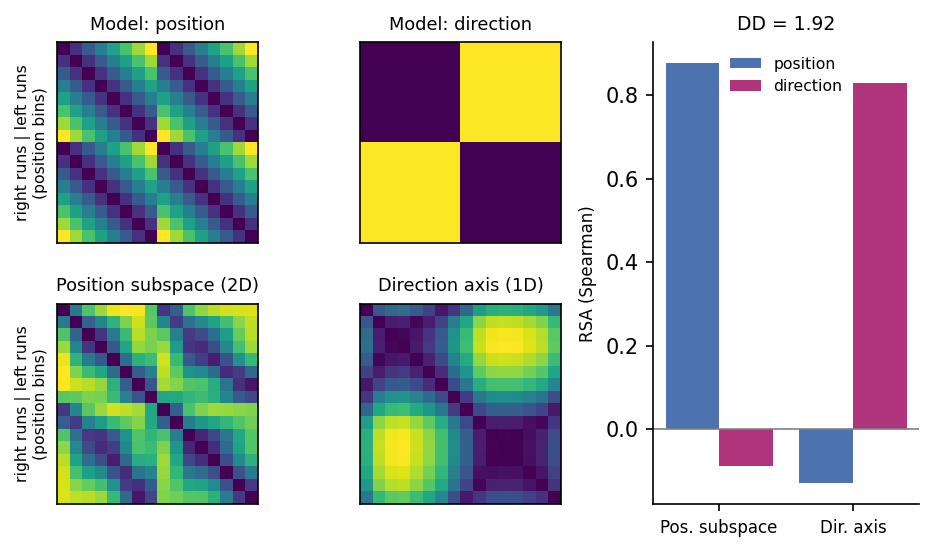

In [23]:
import scipy.stats
import matplotlib.gridspec as gridspec

MIN_PER_CONDITION = 20   # skip conditions with too few time points

# Condition means of the validation embedding (8 position bins x 2 directions)
bins, right = pos_bins(full_val_labels[:, 0]), full_val_labels[:, 1] == 1
means, centers, dirs = [], [], []
for r in (True, False):
    for b in range(len(POS_EDGES) - 1):
        sel = (bins == b) & (right == r)
        if sel.sum() >= MIN_PER_CONDITION:
            means.append(full_val_embedding[sel].mean(0))
            centers.append((POS_EDGES[b] + POS_EDGES[b + 1]) / 2)
            dirs.append(r)
means, centers, dirs = np.array(means), np.array(centers), np.array(dirs)


def rdm(x):
    return np.linalg.norm(x[:, None] - x[None], axis=-1)


rdms = {
    "Model: position": np.abs(centers[:, None] - centers[None]),
    "Model: direction": (dirs[:, None] != dirs[None]).astype(float),
    f"Position subspace ({pos_subspace.shape[1]}D)": rdm(means @ pos_subspace),
    "Direction axis (1D)": rdm((means @ dir_axis)[:, None]),
}

# RSA: Spearman correlation between the subspace RDMs and the model RDMs
iu = np.triu_indices(len(means), 1)
spaces = list(rdms)[2:]
rsa = np.array([[scipy.stats.spearmanr(rdms[s][iu], rdms[m][iu]).correlation for m in list(rdms)[:2]] for s in spaces])
dd = (rsa[0, 0] - rsa[0, 1]) - (rsa[1, 0] - rsa[1, 1])


fig = plt.figure(figsize=(7.5, 4), dpi=150)
gs = gridspec.GridSpec(
    nrows=2,
    ncols=3,
    width_ratios=[1, 1, 1.2],
    wspace=0.35,
    hspace=0.3,
)

# 2x2 grid for RDMs
rdm_coords = [(0, 0), (0, 1), (1, 0), (1, 1)]
for (r, c), (name, m) in zip(rdm_coords, rdms.items()):
    ax = fig.add_subplot(gs[r, c])
    ax.imshow(m, cmap="viridis")
    ax.set_title(name, fontsize=8.5)
    ax.set_xticks([])
    ax.set_yticks([])
    if c == 0:
        ax.set_ylabel("right runs | left runs\n(position bins)", fontsize=7.5)

# Bar plot spanning both rows in column 2
ax_bar = fig.add_subplot(gs[:, 2])
x = np.arange(len(spaces))
ax_bar.bar(x - 0.2, rsa[:, 0], width=0.4, color="#4C72B0", label="position")
ax_bar.bar(x + 0.2, rsa[:, 1], width=0.4, color="#AF347B", label="direction")
ax_bar.axhline(0, color="grey", lw=0.8)
ax_bar.set_xticks(x)
ax_bar.set_xticklabels(["Pos. subspace", "Dir. axis"], fontsize=8)
ax_bar.set_ylabel("RSA (Spearman)", fontsize=8)
ax_bar.set_title(f"DD = {dd:.2f}", fontsize=9)
ax_bar.legend(frameon=False, fontsize=7.5)
sns.despine(ax=ax_bar)

plt.show()

## How do individual cells contribute to these axes?

The subspace analysis above shows how the *population* encodes position and direction in a disentangled way. We now go back to individual cells and ask how each one contributes to these axes. For this we use a second reference model trained with a Jacobian regulariser (same architecture and data split). For every time point, the attribution `M(t) = J(t)ᵀW` is the effect of each cell on the readout of position, where `J(t)` is the Jacobian of the embedding and `W` is a linear readout of position and direction fitted on the training embedding. 

The readout is fitted on the training split and the attribution is computed on the held-out split. More analyses (averaging across models, controls, statistics) are in the attribution demo notebook.

In [ ]:
# Reference model with the Jacobian regulariser, downloaded from figshare to ./model/ (same item as above), once.
ATTR_MODEL_PATH = "model/261118-hippocampus-xcebra-run0.pt"
if USE_CACHED_MODEL and not os.path.exists(ATTR_MODEL_PATH):
    print("Downloading cached model...")
    import io, requests, zipfile
    url = "https://ndownloader.figshare.com/articles/29275358?private_link=ae8099185f5e2f5e8185"
    response = requests.get(url, timeout=600)
    content = io.BytesIO(response.content)
    if response.status_code == 200 and zipfile.is_zipfile(content):
        os.makedirs(os.path.dirname(ATTR_MODEL_PATH), exist_ok=True)
        with zipfile.ZipFile(content) as archive:
            for member in archive.namelist():
                if os.path.basename(member) == os.path.basename(ATTR_MODEL_PATH):
                    with archive.open(member) as f, open(ATTR_MODEL_PATH, "wb") as out:
                        out.write(f.read())
    if not os.path.exists(ATTR_MODEL_PATH):
        print(f"Download failed (HTTP {response.status_code}). Download {os.path.basename(ATTR_MODEL_PATH)} from "
              "https://figshare.com/s/ae8099185f5e2f5e8185 in a browser and put it in ./model/.")

# The attribution needs a solver with the Jacobian regulariser (architecture as in the training cell above)
attr_model = cebra.models.init("offset10-model", num_neurons=num_neurons, num_units=32, num_output=32)
ckpt = torch.load(ATTR_MODEL_PATH, map_location="cpu", weights_only=False)
attr_model.load_state_dict({k.removeprefix("module."): v for k, v in ckpt["model"].items()}, strict=True)
attr_solver = cebra.solver.UnifiedSolverxCEBRA(
    model=attr_model,
    feature_ranges=[slice(0, 32)],
    regularizer=cebra.models.jacobian_regularizer.JacobianReg(),
    renormalize=True,
    criterion=cebra.models.FixedCosineInfoNCE(temperature=1.0),
    optimizer=torch.optim.AdamW(attr_model.parameters(), lr=3e-4, weight_decay=0.01),
    tqdm_on=False,
)
attr_solver.n_features = int(ckpt["n_features"])
attr_solver.num_sessions = int(ckpt["num_sessions"])
attr_solver = attr_solver.to(device)

In [ ]:
import warnings
from cebra.attribution import fit_feature_readout, feature_attribution_map

NB = 80   # 80 position bins of 0.02 m on the 1.6 m track
inputs_tr = [d.neural for d in train_datasets]
labels_tr = [d.continuous for d in train_datasets]
inputs_va = [d.neural for d in valid_datasets]
labels_va = [d.continuous for d in valid_datasets]
left = int(attr_solver.model.get_offset().left)


def bin_mean(pos, values):
    """Mean of values (T, N) in each position bin: (N, NB), NaN for empty bins."""
    b = np.clip((pos / 1.6 * NB).astype(int), 0, NB - 1)
    B = np.zeros((len(pos), NB))
    B[np.arange(len(pos)), b] = 1.0
    with np.errstate(invalid="ignore", divide="ignore"):
        return ((B.T @ values) / B.sum(0)[:, None]).T


rate_maps, attr_maps = [], []
for s in range(len(train_datasets)):
    # Readout W: ridge regression from the training embedding to [position, direction], z-scored
    z = attr_solver.transform(inputs_tr, labels_tr, session_id=s, pad_before_transform=False,
                              random_ties=True, seed=0).cpu().numpy()
    rows = labels_tr[s].cpu().numpy()[left:left + len(z)]
    running = (rows[:, 1] == 1) | (rows[:, 2] == 1)
    y = np.stack([rows[:, 0], np.where(running, rows[:, 1] == 1, 0.5)], axis=1)
    with warnings.catch_warnings():   # the readout uses all training rows on purpose; attribution is on the held-out split
        warnings.simplefilter("ignore")
        W = fit_feature_readout(z, (y - y.mean(0)) / y.std(0), alpha=1.0, train_index=np.arange(len(y)))

    # Attribution M(t) = J(t)^T W on the held-out split: (T, all neurons, 2), column 0 = position
    M = feature_attribution_map(attr_solver, inputs_va, W, labels=labels_va, session_id=s,
                                average=False, random_ties=True, seed=0)
    n0 = sum(x.shape[1] for x in inputs_va[:s])
    M_pos = M[:, n0:n0 + inputs_va[s].shape[1], 0]      # cells of rat s only

    # Training rate map and mean held-out attribution per position bin, running rows of both directions pooled
    neural = inputs_tr[s].cpu().numpy()[left:left + len(z)]
    rate_maps.append(bin_mean(rows[running, 0], neural[running]))
    rows_va = labels_va[s].cpu().numpy()[left:left + len(M_pos)]
    run_va = (rows_va[:, 1] == 1) | (rows_va[:, 2] == 1)
    attr_maps.append(bin_mean(rows_va[run_va, 0], M_pos[run_va]))

rate_maps, attr_maps = np.concatenate(rate_maps), np.concatenate(attr_maps)

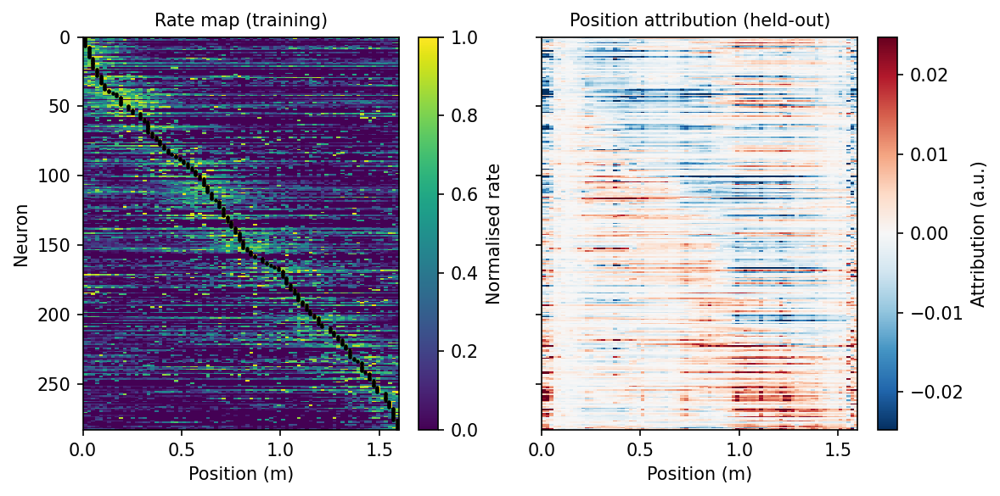

In [ ]:
# All rats pooled, silent cells dropped, cells sorted by the position of their training rate peak
keep = np.nanmax(rate_maps, axis=1) > 0
rate_maps, attr_maps = rate_maps[keep], attr_maps[keep]
order = np.argsort(np.nanargmax(rate_maps, axis=1))
rate_norm = rate_maps[order] / np.nanmax(rate_maps[order], axis=1, keepdims=True)
attr_sorted = attr_maps[order]
peaks = np.nanargmax(rate_norm, axis=1)

vmax = np.nanpercentile(np.abs(attr_sorted), 99)   # one symmetric scale for the attribution
extent = [0, 1.6, len(order), 0]
fig, axes = plt.subplots(1, 2, figsize=(8, 4), dpi=150, sharey=True)
im0 = axes[0].imshow(rate_norm, aspect="auto", cmap="viridis", vmin=0, vmax=1, extent=extent, interpolation="nearest")
axes[0].scatter((peaks + 0.5) * 1.6 / NB, np.arange(len(order)) + 0.5, s=1.5, c="k")
im1 = axes[1].imshow(attr_sorted, aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax, extent=extent, interpolation="nearest")
for ax, im, title, label in zip(axes, [im0, im1], ["Rate map (training)", "Position attribution (held-out)"],
                                ["Normalised rate", "Attribution (a.u.)"]):
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Position (m)")
    fig.colorbar(im, ax=ax, label=label)
axes[0].set_ylabel("Neuron")
plt.tight_layout()
plt.show()

🗺️ *Reading the map:* a cell with a place field pushes the decoded position up (positive, red) when the animal is below its field and down (negative, blue) when it is above, with a sign change at the field.

## Overlapping ranges of behaviors

Now, let's consider what happends when the full range of behavior is not available in some recordings. What will their embeddings look like? Unified CEBRA can recover the latent trajctory over the complete behavioral range through a *global embedding*. 

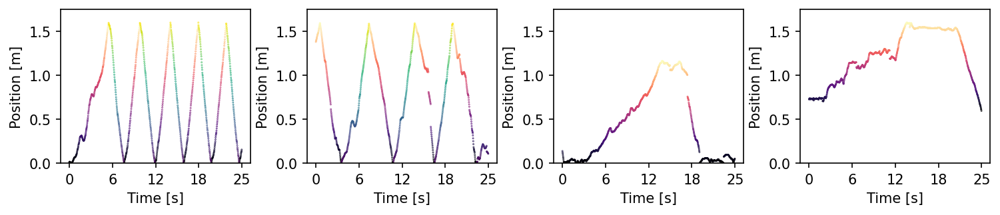

In [24]:
fig = plt.figure(figsize=(12,2), dpi=150)
plt.subplots_adjust(wspace = 0.3)

n_points = 1000 # We only select the first 1000 sample points of each dataset

for i in range(len(train_datasets)):
    ax = plt.subplot(1, 4, i+1)

    label = train_datasets[i].continuous[:n_points,:].cpu()

    r_ind = label[:, 1] == 1
    l_ind = label[:, 2] == 1

    r_cmap = "magma"
    l_cmap = "viridis"
    r_c = label[r_ind, 0]
    l_c = label[l_ind, 0]

    ax.scatter(np.arange(n_points)[r_ind], label[r_ind,0], c=r_c, cmap = r_cmap, s=0.1)
    ax.scatter(np.arange(n_points)[l_ind], label[l_ind,0], c=l_c, cmap = l_cmap, s=0.1)
    ax.set_ylabel('Position [m]')
    ax.set_xlabel('Time [s]')
    ax.set_ylim([0, 1.75])
    ax.set_xticks(np.linspace(0, n_points, 5), np.linspace(0, 0.025*n_points, 5, dtype = int))
plt.show()

We can see that Rat 3 and 4 on that part of the session do not cover the full range of positions and directions in the linear track.

In [25]:
# Create the 1000-samples dataset
shorter_train = train_datasets
for i in range(len(train_datasets)):
    shorter_train[i].neural = train_datasets[i].neural[:n_points,:]
    shorter_train[i].continuous = train_datasets[i].continuous[:n_points, :]

In [26]:
# Compute the embeddings, similarly to before with the same solver
embeddings = {}
for i in range(len(shorter_train)):
    embeddings[i] = solver.transform([shorter_train[j].neural for j in range(len(shorter_train))],
                                     [shorter_train[j].continuous for j in range(len(shorter_train))],
                                     session_id = i,
                                     batch_size=300).cpu().numpy()

In [27]:
markersize=2
cols = len(embeddings)
fig = make_subplots(
    rows=1,
    cols=cols,
    specs=[[{"type": "scatter3d"}, {"type": "scatter3d"}, {"type": "scatter3d"}, {"type": "scatter3d"}]],
    subplot_titles=tuple(
        np.array(
            [f"Rat {str(i+1)}" for i in range(len(embeddings))]
        )
    ),
    vertical_spacing=0,
    horizontal_spacing=0.0,
)

for i in range(len(embeddings)):
    label = shorter_train[i].continuous.cpu().numpy()

    r_ind = label[:, 1] == 1
    l_ind = label[:, 2] == 1
    r_map = "magma"
    l_map = "viridis"
    r_c = label[r_ind, 0]
    l_c = label[l_ind, 0]

    fig = plot_embedding_interactive(
        embeddings[i][r_ind],
        r_c,
        cmap=r_map,
        axis=fig,
        row=1,
        col=i+1,
        opacity=alpha,
        markersize=markersize,
        title="",
    )

    fig = plot_embedding_interactive(
        embeddings[i][l_ind],
        l_c,
        cmap=l_map,
        axis=fig,
        row=1,
        col=i+1,
        opacity=alpha,
        markersize=markersize,
        title="",
    )

dict_layout = dict(
        xaxis = dict(
            backgroundcolor="rgba(0, 0, 0, 0)",
            gridcolor="rgba(0, 0, 0, 0)",
            showbackground=True,
            zerolinecolor="white",
        ),
        yaxis = dict(
            backgroundcolor="rgba(0, 0, 0, 0)",
            gridcolor="rgba(0, 0, 0, 0)",
            showbackground=True,
            zerolinecolor="white",
        ),
        zaxis = dict(
            backgroundcolor="rgba(0, 0, 0, 0)",
            gridcolor="rgba(0, 0, 0, 0)",
            showbackground=True,
            zerolinecolor="white",
        ))

fig.update_layout(
    scene = dict_layout,
    scene2= dict_layout,
    scene3= dict_layout,
    scene4= dict_layout,
    margin=dict(l=0, r=0, t=0, b=0),
    width=650,
    height=200,
)

fig.show(renderer="notebook")

Consequently, we do see that the embeddings based on the behavior for Rat 3 and 4 are not complete but the trajectory is still very clearly represented in the common latent space, as it was trained across recordings on the full range of behaviors.

NOTE: Unified CEBRA embeddings represent the latent space over all the neurons used at training, here all the neurons across the rats. The difference from one session-indexed embedding to the other is only the behavior that was used to align the sessions.

Now, how do we get a global embedding visualization? Because the embeddings are infered from the latent space we can just consider all of them all together (concatenation in time).

In [28]:
# Assemble all behaviors together
embeddings = []
for i in range(len(shorter_train)):
    embeddings.append(solver.transform([shorter_train[j].neural for j in range(len(shorter_train))],
                                     [shorter_train[j].continuous for j in range(len(shorter_train))], #NOTE: labels at inference
                                     session_id = i,
                                     batch_size=300).cpu().numpy())
embeddings = np.concatenate(embeddings)

In [29]:

fig = make_subplots(
    rows=1,
    cols=1,
    specs=[[{"type": "scatter3d"}]],
    vertical_spacing=0,
    horizontal_spacing=0.0,
)

# We concatenate the behaviors as well
label = [shorter_train[i].continuous.cpu().numpy() for i in range(len(shorter_train))]
label = np.concatenate(label)

r_ind = label[:, 1] == 1
l_ind = label[:, 2] == 1
r_c = label[r_ind, 0]
l_c = label[l_ind, 0]

fig = plot_embedding_interactive(
    embeddings[r_ind],
    r_c,
    cmap=r_map,
    axis=fig,
    row=1,
    col=1,
    opacity=alpha,
    markersize=markersize,
    title="",
)

fig = plot_embedding_interactive(
    embeddings[l_ind],
    l_c,
    cmap=l_map,
    axis=fig,
    row=1,
    col=1,
    markersize=markersize,
    opacity=alpha,
    title="",
)

dict_layout = dict(
        xaxis = dict(
            backgroundcolor="rgba(0, 0, 0, 0)",
            gridcolor="rgba(0, 0, 0, 0)",
            showbackground=True,
            zerolinecolor="white",
        ),
        yaxis = dict(
            backgroundcolor="rgba(0, 0, 0, 0)",
            gridcolor="rgba(0, 0, 0, 0)",
            showbackground=True,
            zerolinecolor="white",
        ),
        zaxis = dict(
            backgroundcolor="rgba(0, 0, 0, 0)",
            gridcolor="rgba(0, 0, 0, 0)",
            showbackground=True,
            zerolinecolor="white",
        ))

fig.update_layout(
    scene = dict_layout,
)

fig.show(
    renderer="notebook",
    width=600,
    height=600,
)